# Session 6 - Q2. Edge Detection

Detect edges in a grayscale image using:
1. Roberts operator
2. Prewitt operator
3. Sobel operator
4. Laplacian operator
5. Canny edge detector

Compare the edge maps produced by the different operators.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [2]:
image_path = "input.jpg"
image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

if image is None:
    raise FileNotFoundError("Image could not be loaded.")

In [3]:
# Roberts operator
roberts_x = np.array([
    [1, 0],
    [0, -1]
], dtype=np.float32)

roberts_y = np.array([
    [0, 1],
    [-1, 0]
], dtype=np.float32)

gx = cv2.filter2D(image, cv2.CV_32F, roberts_x)
gy = cv2.filter2D(image, cv2.CV_32F, roberts_y)
roberts = cv2.convertScaleAbs(cv2.magnitude(gx, gy))

# Prewitt operator
prewitt_x = np.array([
    [-1, 0, 1],
    [-1, 0, 1],
    [-1, 0, 1]
], dtype=np.float32)

prewitt_y = np.array([
    [-1, -1, -1],
    [0, 0, 0],
    [1, 1, 1]
], dtype=np.float32)

gx = cv2.filter2D(image, cv2.CV_32F, prewitt_x)
gy = cv2.filter2D(image, cv2.CV_32F, prewitt_y)
prewitt = cv2.convertScaleAbs(cv2.magnitude(gx, gy))

In [4]:
# Sobel operator
sobel_x = cv2.Sobel(image, cv2.CV_32F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(image, cv2.CV_32F, 0, 1, ksize=3)
sobel = cv2.convertScaleAbs(cv2.magnitude(sobel_x, sobel_y))

# Laplacian operator
laplacian = cv2.Laplacian(image, cv2.CV_64F)
laplacian = cv2.convertScaleAbs(laplacian)

# Canny edge detector
canny = cv2.Canny(image, 100, 200)

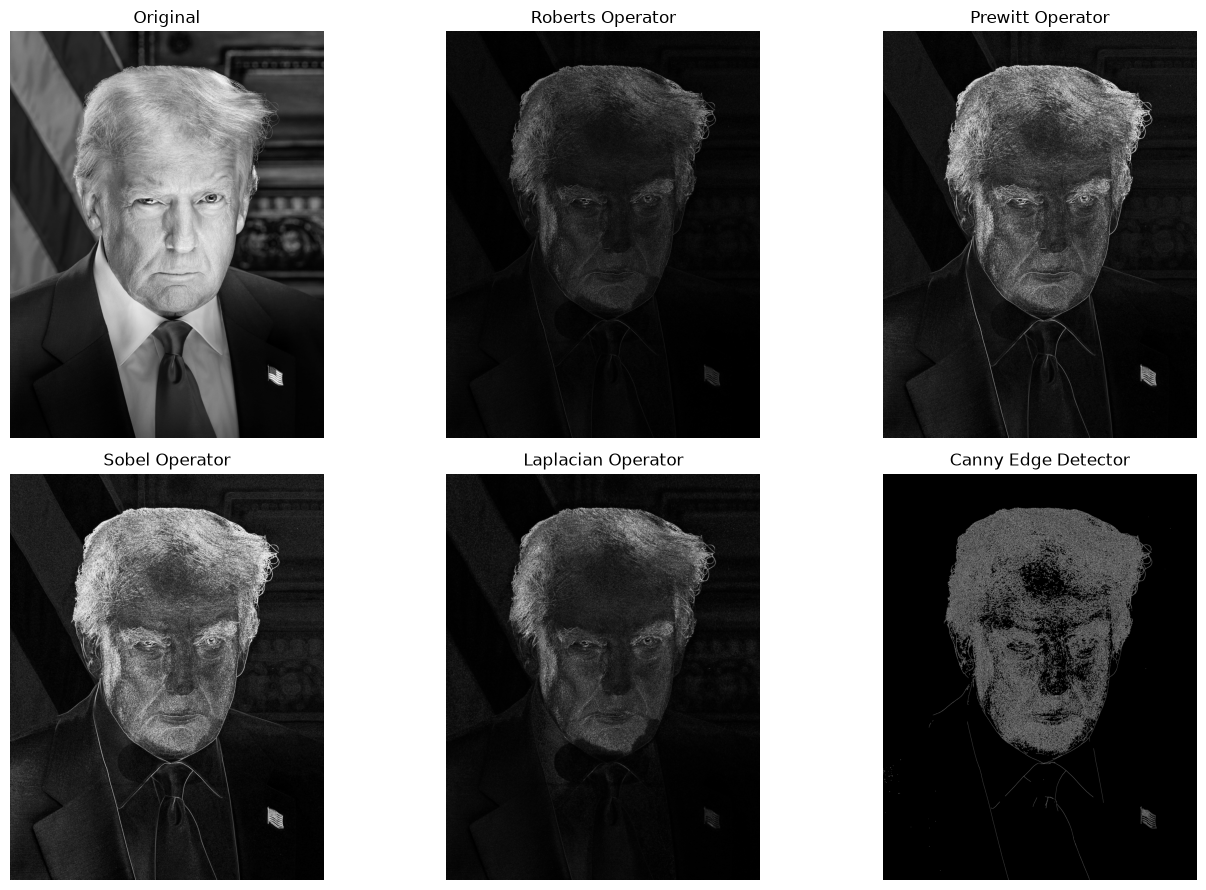

In [5]:
images = [image, roberts, prewitt, sobel, laplacian, canny]
titles = [
    "Original", "Roberts Operator", "Prewitt Operator",
    "Sobel Operator", "Laplacian Operator", "Canny Edge Detector"
]

plt.figure(figsize=(14, 9))

for i in range(len(images)):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], cmap="gray")
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()